In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

In [2]:
# 1. Serie de ejemplo: la pendiente (tasa de crecimiento)
np.random.seed(0) #fijo semilla de generador de #s aleatorios
n = 50  #cantidad de puntos en el tiempo
pendiente = np.concatenate([np.full(30, 0.3), np.full(20, 1.2)])
#np.full(30, 0.3) crea un arreglo 30 elementos, rellenado con valor 0.3
pendiente

array([0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3,
       0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3,
       0.3, 0.3, 0.3, 0.3, 1.2, 1.2, 1.2, 1.2, 1.2, 1.2, 1.2, 1.2, 1.2,
       1.2, 1.2, 1.2, 1.2, 1.2, 1.2, 1.2, 1.2, 1.2, 1.2, 1.2])

In [3]:
# A esa pendiente le sumo ruido aleatorio, simulando variaciones reales
incrementos = pendiente + np.random.normal(0, 1, n) #u=0, sigma=1
incrementos

array([ 2.06405235,  0.70015721,  1.27873798,  2.5408932 ,  2.16755799,
       -0.67727788,  1.25008842,  0.14864279,  0.19678115,  0.7105985 ,
        0.44404357,  1.75427351,  1.06103773,  0.42167502,  0.74386323,
        0.63367433,  1.79407907,  0.09484174,  0.6130677 , -0.55409574,
       -2.25298982,  0.9536186 ,  1.1644362 , -0.44216502,  2.56975462,
       -1.15436567,  0.34575852,  0.11281615,  1.83277921,  1.76935877,
        1.35494743,  1.57816252,  0.31221425, -0.78079647,  0.85208785,
        1.35634897,  2.43029068,  2.40237985,  0.81267318,  0.89769725,
        0.15144703, -0.22001794, -0.50627019,  3.1507754 ,  0.69034782,
        0.7619257 , -0.05279536,  1.97749036, -0.41389785,  0.98725972])

In [4]:
np.cumsum(incrementos)

array([ 2.06405235,  2.76420955,  4.04294754,  6.58384074,  8.75139873,
        8.07412085,  9.32420927,  9.47285206,  9.66963321, 10.38023171,
       10.82427528, 12.57854879, 13.63958651, 14.06126153, 14.80512476,
       15.43879909, 17.23287816, 17.3277199 , 17.9407876 , 17.38669186,
       15.13370204, 16.08732064, 17.25175684, 16.80959182, 19.37934644,
       18.22498077, 18.57073928, 18.68355543, 20.51633465, 22.28569342,
       23.64064084, 25.21880336, 25.53101762, 24.75022115, 25.602309  ,
       26.95865797, 29.38894865, 31.7913285 , 32.60400168, 33.50169893,
       33.65314596, 33.43312803, 32.92685784, 36.07763323, 36.76798105,
       37.52990675, 37.47711139, 39.45460174, 39.0407039 , 40.02796362])

In [5]:
serie = pd.Series(50 + np.cumsum(incrementos))

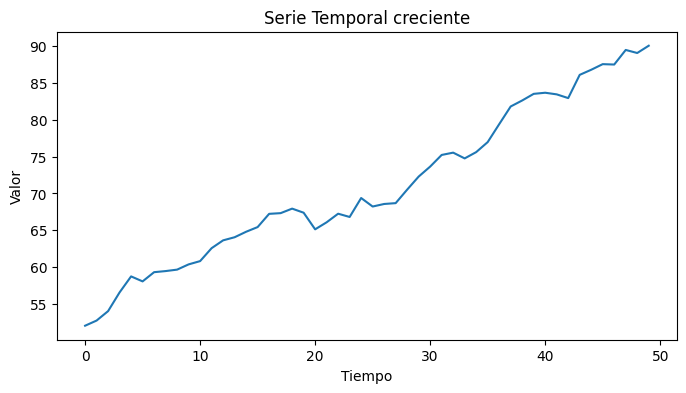

In [6]:
plt.figure(figsize=(8, 4))
plt.plot(serie)
plt.title("Serie Temporal creciente")
plt.xlabel("Tiempo")
plt.ylabel("Valor")
plt.show()

In [7]:
# 2. Separar train (histórico) y test (últimos 10 valores)
train=  serie[:-10] #Todos los elementos excepto los últimos 10
test =  serie[-10:] #Toma únicamente los últimos 10 elementos.

In [ ]:
#train
#train.shape
#train.values

In [8]:
# 3. Modelo ARIMA(1,1,1)
modelo_arima = ARIMA(train, order=(1, 1, 1)).fit()
# AR=1 Usa el valor del periodo inmediatamente anterior para predecir el valor actual.
# I=1 Aplica 1 diferencia a los datos y_t - y_{t-1}. vuelve a la serie estacionaria.
# MA=1: Incorpora el error del periodo anterior para corregir la predicción actual.

In [9]:
# Proyecion de los siguientes 10 pasos en el tiempo
pred_arima = modelo_arima.forecast(steps=10)

In [10]:
# 4. Modelo de Regresión Lineal (Ventas = b0 + b1*t)
# Debo crear t_train y t_test que seras mi variable predictura/feature X
# Crear 2 series, de 0 a 39, de 40 a 49.
#np.arange(start, stop)
t_train = np.arange(len(train)).reshape(-1, 1) # valores de 0,1,...,39
t_test = np.arange(len(train), len(train) + len(test)).reshape(-1, 1)# valores de 40,41,...,49
t_train.shape

(40, 1)

In [11]:
LR = LinearRegression().fit(t_train, train.values)
pred_LR = LR.predict(t_test) #prediccion de 10 datos futuros 40,41,...,49

In [12]:
# 5. Comparar error de pronóstico
rmse_arima = np.sqrt(mean_squared_error(test, pred_arima))
rmse_reg = np.sqrt(mean_squared_error(test, pred_LR))
print(f"RMSE Regresión Lineal: {rmse_reg}")
print(f"RMSE ARIMA(1,1,1):     {rmse_arima}")

RMSE Regresión Lineal: 2.934852245470168
RMSE ARIMA(1,1,1):     1.3297794010710227


Text(0.5, 1.0, 'ARIMA vs Regresión Lineal')

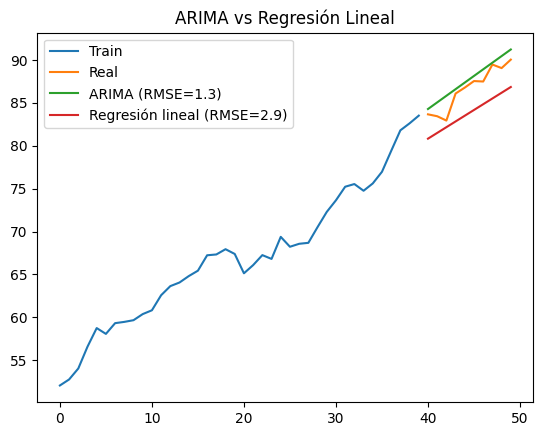

In [13]:
# 6. Graficar
plt.plot(train.index, train, label="Train")
plt.plot(test.index, test, label="Real")
plt.plot(test.index, pred_arima, label=f"ARIMA (RMSE={rmse_arima:.1f})")
plt.plot(test.index, pred_LR, label=f"Regresión lineal (RMSE={rmse_reg:.1f})")
plt.legend()
plt.title("ARIMA vs Regresión Lineal")